# tiền xử lý

## overview data

## thư viện sử dụng

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## Đọc dữ liệu

In [2]:
path = Path(r"..\..\data\raw\train.csv")

df = pd.read_csv(path)
df.head()

,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


* Bộ dữ liệu có 14.396 bài hát (train) và 3.600 bài (test), gồm 16 cột đặc trưng (features): thông tin bài hát (Artist Name, Track Name, Popularity) và các đặc trưng âm thanh của Spotify (danceability, energy, loudness, tempo...). Dựa trên các đặc trưng này, mô hình phải dự đoán **thể loại nhạc**, được biểu thị bằng cột nhãn (label) `Class` (11 lớp, từ 0 đến 10).

* Chúng ta sẽ loại bỏ cột Id vì cột này không cần thiết cho quá trình huấn luyện mô hình.

In [3]:
df = df.drop('Id', axis=1)
df.head(3)

,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14396 entries, 0 to 14395
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Artist Name         14396 non-null  str    
 1   Track Name          14396 non-null  str    
 2   Popularity          14063 non-null  float64
 3   danceability        14396 non-null  float64
 4   energy              14396 non-null  float64
 5   key                 12787 non-null  float64
 6   loudness            14396 non-null  float64
 7   mode                14396 non-null  int64  
 8   speechiness         14396 non-null  float64
 9   acousticness        14396 non-null  float64
 10  instrumentalness    10855 non-null  float64
 11  liveness            14396 non-null  float64
 12  valence             14396 non-null  float64
 13  tempo               14396 non-null  float64
 14  duration_in min/ms  14396 non-null  float64
 15  time_signature      14396 non-null  int64  
 16  Class          

## Phân tích sự phân bố nhãn Class

Class
0      500
1     1098
2     1018
3      322
4      310
5     1157
6     2069
7      461
8     1483
9     2019
10    3959
Name: count, dtype: int64


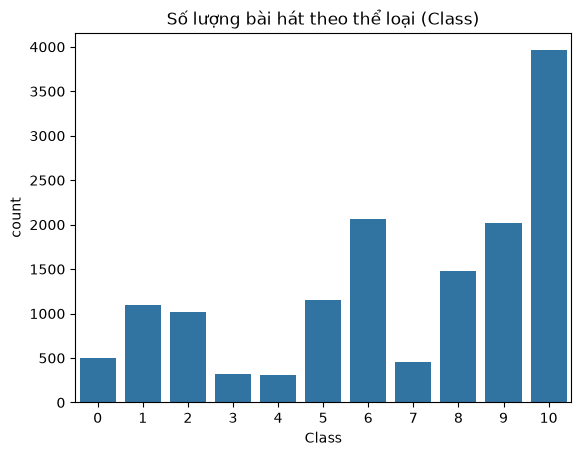

In [5]:
class_counts = df['Class'].value_counts().sort_index()
print(class_counts)

sns.countplot(data=df, x='Class')
plt.title('Số lượng bài hát theo thể loại (Class)')
plt.show()

* Theo mô tả gốc của bộ dữ liệu (Kaggle - Music Genre Classification), các nhãn tương ứng: 0 Acoustic/Folk, 1 Alt_Music, 2 Blues, 3 Bollywood, 4 Country, 5 HipHop, 6 Indie Alt, 7 Instrumental, 8 Metal, 9 Pop, 10 Rock (cần đối chiếu lại với nguồn tải về).
* Dữ liệu **mất cân bằng mạnh**: lớp 10 có 3.959 bài trong khi lớp 4 chỉ có 310 bài (chênh ~13 lần). Khi chia train/validation phải dùng `stratify=y`, và nên đánh giá bằng F1-macro thay vì chỉ dùng accuracy.

## Phân loại dữ liệu

In [6]:
numberical_continuos = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                        "instrumentalness", "liveness", "valence", "tempo", "duration_in min/ms"]
numberical_count = ["Popularity"]
ordinal_categorical = []
nominal_categorical = ["Artist Name", "Track Name"]
Binary = ["mode"]
Special_Coded_Category = ["key", "time_signature"]
Target = ["Class"]
Id = ["Id"]

- Biến số liên tục (Numerical Continuous): các đặc trưng âm thanh. Phần lớn nằm trong khoảng [0, 1] (danceability, energy, speechiness, acousticness, instrumentalness, liveness, valence), riêng loudness (dB, âm), tempo (BPM) và duration có thang đo khác hẳn ⇒ bắt buộc chuẩn hóa (StandardScaler) nếu dùng mô hình dựa trên khoảng cách (KNN, SVM, Logistic Regression).
- Biến số đếm / điểm số (Numerical Count): Popularity là điểm nguyên từ 1 đến 100. Có thứ tự và khoảng cách, nhưng không phải phép đo vật lý ⇒ dùng tương quan Spearman sẽ phản ánh xu hướng tốt hơn Pearson.
- Biến hạng mục có thứ bậc (Ordinal Categorical): bộ dữ liệu này **không có** cột nào thuộc nhóm này.
- Biến hạng mục định danh (Nominal Categorical): Artist Name (7.913 giá trị khác nhau) và Track Name (12.455 giá trị). Số lượng hạng mục quá lớn (high cardinality) ⇒ **không** One-Hot được. Track Name gần như là định danh nên loại bỏ; Artist Name có thể bỏ hoặc dùng Target/Frequency Encoding (phải làm trong cross-validation để tránh rò rỉ nhãn).
- Biến nhị phân (Binary): mode (1 = major / giọng trưởng, 0 = minor / giọng thứ), đã ở dạng 0/1, giữ nguyên.
- Hạng mục mã hóa đặc biệt (Special Coded Category): đây là nhóm quan trọng nhất cần lưu ý.
- - Biến key (tông nhạc) có giá trị 0 - 11 theo quy ước Spotify (0 = C, 1 = C♯/D♭, ..., 11 = B). Đây là các nốt nhạc **xoay vòng**, không có quan hệ lớn hơn / nhỏ hơn: key 11 (B) không "lớn gấp 11 lần" key 1, và B lại nằm ngay cạnh C. Giữ dạng số sẽ tạo ra quan hệ toán học giả (spurious relationships) ⇒ chuyển sang string và One-Hot Encoding.
- - Tương tự, time_signature (nhịp: 1, 3, 4, 5) là nhãn của loại nhịp chứ không phải đại lượng liên tục ⇒ chuyển sang string và One-Hot Encoding.

## kiểm tra dữ liệu thiếu

In [7]:
def missing_values(data:pd.DataFrame,cols):
    for col in cols:
        per=len(data[col])
        missingper=(data[col].isnull().sum())/per*100
        if(missingper >0):
            print(f"{col}:{missingper:.2f}")

In [8]:
cols=df.columns.to_list()
missing_values(df,cols)

Popularity:2.31
key:11.18
instrumentalness:24.60


Có 3 cột bị thiếu: Popularity (~2,31%), key (~11,18%), instrumentalness (~24,60%). Kiểm tra kỹ hơn xem các giá trị thiếu có mang ý nghĩa gì không:

In [9]:
# key: giá trị nào đang có trong dữ liệu?
print(sorted(df['key'].dropna().unique()))
print(df['key'].value_counts(dropna=False).sort_index())

[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0)]
key
1.0     1351
2.0     1582
3.0      411
4.0     1252
5.0     1115
6.0      963
7.0     1650
8.0      872
9.0     1590
10.0     825
11.0    1176
NaN     1609
Name: count, dtype: int64


In [10]:
# instrumentalness: giá trị nhỏ nhất là bao nhiêu? có giá trị 0 nào không?
print('min:', df['instrumentalness'].min())
print('số dòng = 0:', (df['instrumentalness'] == 0).sum())

# tỉ lệ thiếu instrumentalness theo từng Class
df.groupby('Class')['instrumentalness'].apply(lambda s: s.isnull().mean() * 100).round(2)

min: 1e-06
số dòng = 0: 0


Class
0     24.20
1     12.75
2     10.81
3     24.22
4     53.55
5     61.37
6     10.78
7      0.22
8      8.50
9     49.48
10    21.90
Name: instrumentalness, dtype: float64

* Quy trình xác định missing values gồm 3 cơ sở:
- Thiếu do giá trị bị mã hóa thành rỗng: cột key chỉ có giá trị 1 - 11, **hoàn toàn không có key 0 (nốt C)**, và số dòng thiếu (1.609) xấp xỉ tần suất của một tông nhạc phổ biến ⇒ các ô rỗng chính là key = 0 bị ghi thành NaN khi xuất dữ liệu.
- Vắng mặt thông số vật lý: instrumentalness có min = 1e-06 và không có giá trị 0 nào, dù đây là cột rất hay có giá trị bằng 0 (bài có lời). Tỉ lệ thiếu cao nhất ở HipHop (lớp 5, ~61%) và Pop (lớp 9, ~49%) - các thể loại nhiều lời hát - và bằng 0% ở Instrumental (lớp 7) ⇒ NaN ở đây rất có thể nghĩa là "không có nhạc cụ thuần" = 0. Vì tỉ lệ thiếu khác nhau rõ giữa các lớp nên tạo thêm cột cờ `instrumentalness_missing` để giữ lại thông tin này cho mô hình.
- Khuyết thiếu thực sự: Popularity bị thiếu ngẫu nhiên, tỉ lệ nhỏ ⇒ điền median.

# phát hiện và đánh giá outlies

- Định nghĩa Ngoại lai trong ngữ cảnh Music Genre: những bài hát có giá trị đặc trưng nằm ngoài khoảng hợp lý về mặt vật lý (ví dụ thời lượng chỉ vài mili giây, loudness > 0 dB) hoặc dữ liệu bị ghi sai đơn vị. Các giá trị chỉ "hiếm" (ví dụ bài speechiness cao như rap/podcast, bài live có liveness cao) là đặc trưng thật của thể loại, **không** phải ngoại lai.

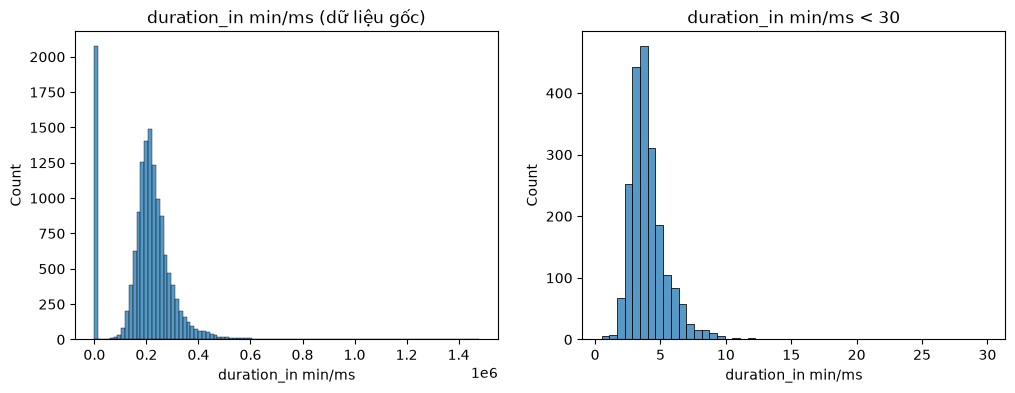

Số dòng có duration < 30: 2075
Số dòng có 30 <= duration < 10000: 0


Class
0     500
3     322
4     310
7     461
9     339
10    143
dtype: int64

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['duration_in min/ms'], bins=100, ax=axes[0])
axes[0].set_title('duration_in min/ms (dữ liệu gốc)')
sns.histplot(df.loc[df['duration_in min/ms'] < 30, 'duration_in min/ms'], bins=50, ax=axes[1])
axes[1].set_title('duration_in min/ms < 30')
plt.show()

small = df['duration_in min/ms'] < 30
print('Số dòng có duration < 30:', small.sum())
print('Số dòng có 30 <= duration < 10000:', ((df['duration_in min/ms'] >= 30) & (df['duration_in min/ms'] < 10000)).sum())
df[small].groupby('Class').size()

Tên cột `duration_in min/ms` đã gợi ý vấn đề: cột này **trộn 2 đơn vị**. Có 2.075 dòng giá trị < 30 (khoảng 0,5 - 30) - đây là **phút**, còn các dòng khác (trung vị ~209.000) là **mili giây**. Giữa 30 và 10.000 không có dòng nào, nên ranh giới phân tách rất rõ. Nếu dùng IQR hay z-score, cả 2.075 dòng này sẽ bị coi là ngoại lai và bị xóa sai, trong khi thực chất chỉ cần đổi đơn vị: phút × 60.000 = mili giây.

Lưu ý: các lớp 0, 3, 4, 7 có **100%** dòng ở đơn vị phút (lớp 9 có 339 dòng và lớp 10 có 143 dòng, còn các lớp khác không có dòng nào) ⇒ đơn vị đo đang tiết lộ nhãn. Sau khi đổi về cùng đơn vị, mô hình sẽ không học được "mẹo" này nữa (đúng ý muốn, vì dữ liệu thật sẽ không có quy luật như vậy).

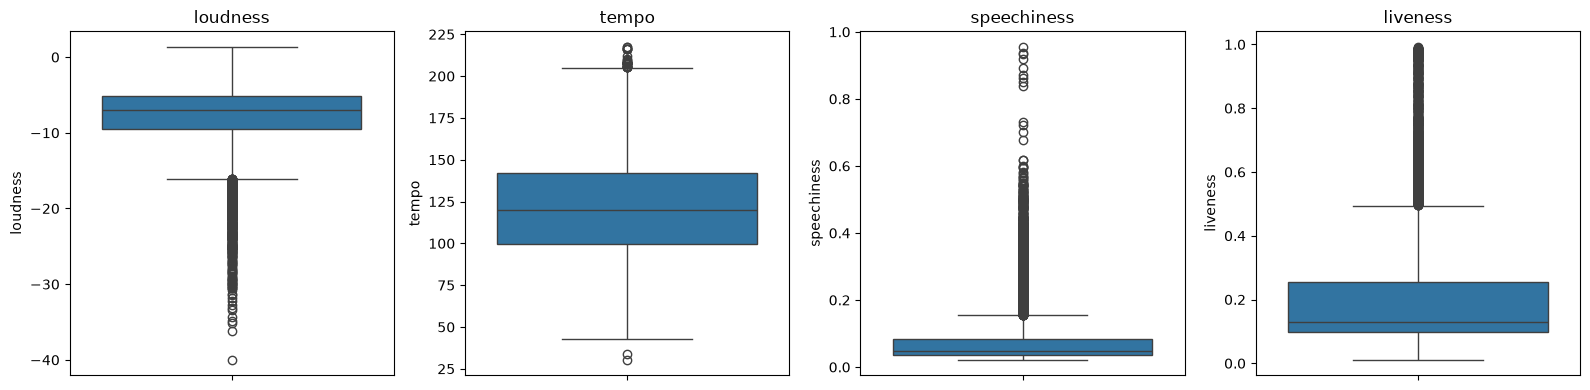

loudness > 0 dB: 7
time_signature
1       87
3      994
4    13149
5      166
Name: count, dtype: int64


In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['loudness', 'tempo', 'speechiness', 'liveness']):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

print('loudness > 0 dB:', (df['loudness'] > 0).sum())
print(df['time_signature'].value_counts().sort_index())

- loudness: chỉ có 7 bài > 0 dB (lớn nhất 1,34 dB), có thể xảy ra với các bản master rất lớn ⇒ giữ lại.
- tempo: nằm trong khoảng 30 - 217 BPM, hợp lý với âm nhạc ⇒ giữ lại.
- speechiness, liveness: có đuôi dài bên phải nhưng đây là đặc trưng thể loại (rap, bản thu live) ⇒ giữ lại, nếu cần thì dùng log/Robust scaling thay vì xóa.
- time_signature = 1 chỉ có 87 dòng (nhịp 1/4 rất hiếm trong thực tế, nhiều khả năng do Spotify đoán sai) ⇒ giữ lại, nhưng khi One-Hot có thể gộp vào nhóm hiếm.

## kiểm tra dữ liệu trùng lặp

In [13]:
print('Dòng trùng hoàn toàn:', df.duplicated().sum())
print('Trùng Artist + Track:', df.duplicated(['Artist Name', 'Track Name']).sum())

multi_class = df.groupby(['Artist Name', 'Track Name'])['Class'].nunique()
print('Số bài xuất hiện với nhiều Class khác nhau:', (multi_class > 1).sum())

Dòng trùng hoàn toàn: 0
Trùng Artist + Track: 1220
Số bài xuất hiện với nhiều Class khác nhau: 1043


Không có dòng trùng hoàn toàn, nhưng có 1.220 dòng trùng Artist + Track, và 1.043 bài hát được gán **nhiều thể loại khác nhau** (một bài vừa là Rock vừa là Indie Alt...). Đây là bản chất dữ liệu (một bài có thể thuộc nhiều thể loại) chứ không phải lỗi, nên **không xóa**. Tuy nhiên khi chia train/validation nên dùng `GroupKFold` theo bài hát để cùng một bài không nằm ở cả 2 tập.

vậy tôi Ngô Nguyên đề xuất các điền các missing values và xử lý outlies

## điền các giá trị 0

In [14]:
ZERO_FILL_COLS = [
    "key",               # NaN chính là key = 0 (nốt C)
    "instrumentalness",  # NaN = bài có lời, không có nhạc cụ thuần
]

# Cột cờ đánh dấu dòng bị thiếu (tạo TRƯỚC khi điền)
MISSING_FLAG_COLS = [
    "instrumentalness",
]

## sửa lỗi đơn vị (thay cho việc xóa outlies)

In [15]:
DURATION_COL = "duration_in min/ms"
MINUTE_THRESHOLD = 30      # < 30 là phút, còn lại là mili giây
MINUTE_TO_MS = 60_000

## loại bỏ các cột không dùng cho mô hình

In [16]:
DROP_COLS = [
    "Id",
    "Track Name",   # gần như định danh duy nhất cho mỗi dòng
]

## điền các median và mode cho các cột thiếu thật sự

In [17]:
MEDIAN_FILL_COLS = [
    "Popularity",
]

# Các cột điền bằng Mode
MODE_FILL_COLS = [
]

## áp dụng các bước tiền xử lý
Median được tính **chỉ trên tập train** rồi áp dụng cho cả test, để tránh rò rỉ dữ liệu.

In [18]:
def clean_music(data: pd.DataFrame, fill_values: dict) -> pd.DataFrame:
    data = data.copy()

    # 1. sửa đơn vị duration: phút -> mili giây
    is_minute = data[DURATION_COL] < MINUTE_THRESHOLD
    data.loc[is_minute, DURATION_COL] = data.loc[is_minute, DURATION_COL] * MINUTE_TO_MS
    data = data.rename(columns={DURATION_COL: "duration_ms"})

    # 2. cột cờ missing
    for col in MISSING_FLAG_COLS:
        data[f"{col}_missing"] = data[col].isnull().astype(int)

    # 3. điền 0
    for col in ZERO_FILL_COLS:
        data[col] = data[col].fillna(0)

    # 4. điền median / mode
    for col in MEDIAN_FILL_COLS + MODE_FILL_COLS:
        data[col] = data[col].fillna(fill_values[col])

    # 5. mã hóa đặc biệt: key, time_signature -> string (One-Hot ở bước feature)
    data["key"] = data["key"].astype(int).astype(str)
    data["time_signature"] = data["time_signature"].astype(str)

    # 6. bỏ cột không dùng
    data = data.drop(columns=[c for c in DROP_COLS if c in data.columns])
    return data

In [19]:
train_raw = pd.read_csv(Path(r"..\..\data\raw\train.csv"))
test_raw = pd.read_csv(Path(r"..\..\data\raw\test.csv"))

fill_values = {col: train_raw[col].median() for col in MEDIAN_FILL_COLS}
fill_values.update({col: train_raw[col].mode()[0] for col in MODE_FILL_COLS})

train_clean = clean_music(train_raw, fill_values)
test_clean = clean_music(test_raw, fill_values)

missing_values(train_clean, train_clean.columns.to_list())
missing_values(test_clean, test_clean.columns.to_list())
print(train_clean.shape, test_clean.shape)
train_clean['duration_ms'].describe()

(14396, 17) (3600, 16)


count    1.439600e+04
mean     2.352233e+05
std      8.437299e+04
min      3.009900e+04
25%      1.873330e+05
50%      2.198005e+05
75%      2.624550e+05
max      1.793160e+06
Name: duration_ms, dtype: float64

## lưu dữ liệu đã làm sạch

In [20]:
out_dir = Path(r"..\..\data\clean")
train_clean.to_csv(out_dir / "train_clean.csv", index=False)
test_clean.to_csv(out_dir / "test_clean.csv", index=False)